# Movie Review datasets for Text Preprocessing


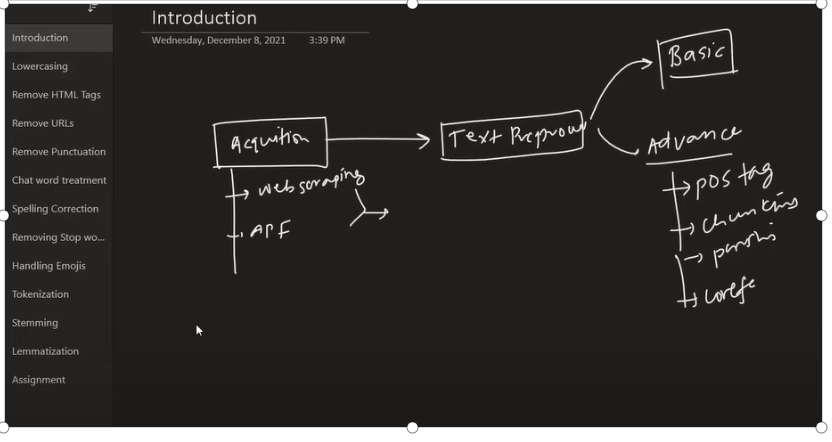

In [ ]:
# data link kaggle
# https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews

In [ ]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Path to dataset files: /kaggle/input/imdb-dataset-of-50k-movie-reviews


In [ ]:
import pandas as pd
import os

# List the files in the downloaded directory to find the CSV file name
# Assuming the CSV file is named 'IMDB Dataset.csv' based on the dataset's common naming
csv_file_path = os.path.join(path, 'IMDB Dataset.csv')

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(csv_file_path)

# Display the first few rows of the DataFrame
display(df.head())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
# DATA USING THE API
# https://www.kaggle.com/code/campusx/text-preprocessing
# https://api.themoviedb.org/3/movie/top_rated?api_key=8265bd1679663a7ea12ac168da84d2e8&language=en-US&page=471
# https://api.themoviedb.org/3/genre/movie/list?api_key=8265bd1679663a7ea12ac168da84d2e8&language=en-US

import random
import string

def generate_random_text(length=100):
    """Generates a random string of specified length."""
    characters = string.ascii_letters + string.digits + string.punctuation + " "
    return ''.join(random.choice(characters) for i in range(length))

# Generate and print a random text
random_text = generate_random_text(200)
print(random_text)



import requests as re

d = re.get("https://api.themoviedb.org/3/movie/top_rated?api_key=8265bd1679663a7ea12ac168da84d2e8&language=en-US&page=471")

d.content



import json

# Assuming 'd.content' contains the byte string from the API response
movie_data = json.loads(d.content)
# movie_data['results'][1]["original_title"]
movie_data


# Extract and print the titles
titles = [movie['title'] for movie in movie_data['results']]
for title in titles:
    print(title)

In [ ]:
r1 = df.iloc[0]["review"]
r1

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [ ]:
# lowercase
# remove html tags
# remove urls
# remove punctuations
# chat word treatment
# spelling corrections
# remove stop words
# Handling Emojis

# Tokenizations
#
# Stemming
# lemmatization
r1.lower()

"one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me.<br /><br />the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word.<br /><br />it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />i would say the main appeal of the show is due to the fa

In [ ]:
df["review"] = df["review"].str.lower()

In [ ]:
import re

def remove_html_tags(text):
    clean = re.compile('<.*?>')
    return re.sub(clean, '', text)

remove_html_tags(r1)

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.I would say the main appeal of the show is due to the fact that it goes where other shows wo

In [ ]:
df["review"] = df["review"].apply(remove_html_tags)

# remove urls

In [ ]:
def remove_urls(text):
    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    return url_pattern.sub(r'', text)

In [ ]:
text = 'this is text https://colab.research.google.com/drive/1CFPsjofZtzzJU4ovwzS5g4z4NX64XnUS#scrollTo=vGdq35dVIJDu add also some urls'
remove_urls(text)

'this is text  add also some urls'

In [ ]:
df['review'] = df['review'].apply(remove_urls)

### remove punctuations

the marks used for dividing writing into sentences and phrases

Here are 14 common punctuation marks with examples: period (.), comma (,), question mark (?), exclamation mark (!), colon (:), semicolon (;), apostrophe ('), quotation marks (" "), hyphen (-), dash (—), parentheses ( ), brackets (), braces ({ }), and ellipsis (...)
![img](https://games4esl.com/wp-content/uploads/Punctuation-Marks.png)

In [ ]:
import string
string.punctuation
exclude = string.punctuation

def remove_punc(text):
  for c in exclude:
    text = text.replace(c, "")
  return text

# remove_punc(r1)
# for all data
df["review"] = df["review"].apply(remove_punc)

### chat word treatment

In [ ]:
chat_words = {
    "AFAIK": "As Far As I Know",
    "AFK": "Away From Keyboard",
    "ASAP": "As Soon As Possible",
    "ATK": "At The Keyboard"}
# https://github.com/rishabhverma17/sms_slang_translator

In [ ]:
def chat_conversion(text):
  new_text = []
  for w in text.split():
      if w.upper() in chat_words:
          new_text.append(chat_words[w.upper()])
      else:
          new_text.append(w)

  return " ".join(new_text)

In [ ]:
chat_conversion("AFK is not working")


### spelling corrections

In [ ]:
# pip install textblob
# python -m textblob.download_corpora
from textblob import TextBlob

In [ ]:
incorrect_text = "Please read the notebook ten and lika the notebok tan"

textBlb = TextBlob(incorrect_text)
textBlb.correct().string

'Please read the notebook an cos and an like the notebook '

### remove stop words

In [ ]:
#  a the of are my
import nltk
from nltk.corpus import stopwords
# corpus --> a collection of written or spoken texts

# Download the stopwords data
nltk.download('stopwords')

# stopwords.words('english')
# add custom words in stopwords

# remove some  words from stopwords

In [ ]:
def remove_stopwords(text):
  new_text = []
  for word in text.split():
    if word in stopwords.words('english'):
      new_text.append('')
    else:
      new_text.append(word)

  x = new_text[:]
  new_text.clear()
  return " ".join(x)

remove_stopwords(r1)

In [ ]:
r1

### Handling Emojis


In [ ]:
import re

# Sample text with an emoji
text = "Hello world! 👋"

# Compile a regex to match emojis
# This pattern includes emoticons and symbols
emoji_pattern = re.compile("[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF]+", flags=re.UNICODE)

# Remove the emoji from the text
text_without_emoji = emoji_pattern.sub(r'', text)

print(text_without_emoji)

Hello world! 


In [ ]:
# Install the emoji library
!pip install emoji
import emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 29.7 MB/s eta 0:00:00
I am happy 😄 and excited 🎉!
I am happy :grinning_face_with_smiling_eyes: and excited :party_popper:!


In [ ]:
# Sample text with emojis
text_with_emojis = "I am happy 😄 and excited 🎉 😡!"

# Convert emojis to their meanings
text_without_emojis = emoji.demojize(text_with_emojis)

print(text_with_emojis)
print(text_without_emojis)

def remove_emoji(text):
   return emoji.demojize(text)


I am happy 😄 and excited 🎉 😡!
I am happy :grinning_face_with_smiling_eyes: and excited :party_popper: :enraged_face:!


In [ ]:
df['review'][0]

'One of the other reviewers has mentioned that after watching just 1 Oz episode youll be hooked They are right as this is exactly what happened with mebr br The first thing that struck me about Oz was its brutality and unflinching scenes of violence which set in right from the word GO Trust me this is not a show for the faint hearted or timid This show pulls no punches with regards to drugs sex or violence Its is hardcore in the classic use of the wordbr br It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary It focuses mainly on Emerald City an experimental section of the prison where all the cells have glass fronts and face inwards so privacy is not high on the agenda Em City is home to manyAryans Muslims gangstas Latinos Christians Italians Irish and moreso scuffles death stares dodgy dealings and shady agreements are never far awaybr br I would say the main appeal of the show is due to the fact that it goes where other shows wouldnt dare Fo

### Tokenizations

In [ ]:
w = " I am learning NLP"
w.split()

['I', 'am', 'learning', 'NLP']

In [ ]:
sent = "i am learning nlp .also i Create some projects on nlp"
sent.split(".")

['i am learning nlp ', 'also i Create some projects on nlp']

In [ ]:
# problem in split
sent = "i am learning nlp . why i learn nlp? also i Create some projects on nlp"
sent.split(".")

['i am learning nlp ', ' why i learn nlp? also i Create some projects on nlp']

In [ ]:
# re use for word level
re.findall("[\w]+",sent)


In [ ]:
re.compile('[.!?]').split(sent)

['i am learning nlp ',
 ' why i learn nlp',
 ' also i Create some projects on nlp']

In [ ]:
# NLTK
import nltk
from nltk.tokenize import word_tokenize,sent_tokenize
# Download the punkt resource
nltk.download('punkt_tab') # This was the missing resource



[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
sent = "i am learning nlp . why i learn nlp? also i Create some projects on nlp!"
word_tokenize(sent)
sent_tokenize(sent)

['i am learning nlp .',
 'why i learn nlp?',
 'also i Create some projects on nlp!']

In [ ]:
s2= 'I have a Ph.D in A.I'
s3 = "we're here to help! mail us at sha@gmail.com"
s4 = "A 5km ride cost $10.50"

In [ ]:
word_tokenize(s3)

['we',
 "'re",
 'here',
 'to',
 'help',
 '!',
 'mail',
 'us',
 'at',
 'sha',
 '@',
 'gmail.com']

In [ ]:
# spacy
import spacy
nlp = spacy.load('en_core_web_sm')

In [ ]:
for i in nlp(s3):
  print(i)

we
're
here
to
help
!
mail
us
at
sha@gmail.com


In [ ]:
df['review_tokens'] = df['review'].apply(word_tokenize)
display(df.head())

#### Stemming: Reduce words to root form (may be crude)
types

1.Porter Stemmer: running → run


2.Snowball Stemmer: More aggressive/stable than Porter



In [ ]:
from nltk.stem import PorterStemmer, SnowballStemmer
ps = PorterStemmer()
ss = SnowballStemmer("english")

print(ps.stem("running"))   # run
print(ss.stem("running"))   # run

run
run


In [ ]:
ps.stem("studies")
ss.stem("studies")

'studi'


### Lemmatization: Reduces words to dictionary form using context



In [ ]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
wn = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
print(wn.lemmatize("running", pos="v"))  # run

run


In [ ]:
wn.lemmatize("running")

'running'

In [ ]:
wn.lemmatize("studies", pos="v")

'study'

In [ ]:
###
### Stemming
### lemmatization
r1.lower()